# Real Estate Housing Price Prediction (OLS, Ridge & Lasso)

**Goal:** Predict `median_house_value` on the California Housing dataset and compare **OLS**, **Ridge (L2)** and **Lasso (L1)** using **RMSE, MAE and R²**.

**Steps:** Load → Missing values → Correlation heatmap → Feature engineering → Multicollinearity (VIF) → Scale + encode → Train OLS / Ridge / Lasso with GridSearchCV → Compare metrics → Predicted vs Actual → Residual analysis.

## 1. Import libraries

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

sns.set_style("whitegrid")
RANDOM_STATE = 42

## 2. Load the dataset

In [2]:
df = pd.read_csv("housing.csv")
print("Shape:", df.shape)
df.head()

Shape: (20640, 10)


,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value,ocean_proximity
0,-122.23,37.88,41.0,880.0,129.0,322.0,126.0,8.3252,452600.0,NEAR BAY
1,-122.22,37.86,21.0,7099.0,1106.0,2401.0,1138.0,8.3014,358500.0,NEAR BAY
2,-122.24,37.85,52.0,1467.0,190.0,496.0,177.0,7.2574,352100.0,NEAR BAY
3,-122.25,37.85,52.0,1274.0,235.0,558.0,219.0,5.6431,341300.0,NEAR BAY
4,-122.25,37.85,52.0,1627.0,280.0,565.0,259.0,3.8462,342200.0,NEAR BAY


In [3]:
df.info()
df.describe().T

<class 'pandas.DataFrame'>
RangeIndex: 20640 entries, 0 to 20639
Data columns (total 10 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   longitude           20640 non-null  float64
 1   latitude            20640 non-null  float64
 2   housing_median_age  20640 non-null  float64
 3   total_rooms         20640 non-null  float64
 4   total_bedrooms      20433 non-null  float64
 5   population          20640 non-null  float64
 6   households          20640 non-null  float64
 7   median_income       20640 non-null  float64
 8   median_house_value  20640 non-null  float64
 9   ocean_proximity     20640 non-null  str    
dtypes: float64(9), str(1)
memory usage: 1.6 MB


,count,mean,std,min,25%,50%,75%,max
longitude,20640.0,-119.569704,2.003532,-124.3500,-121.8000,-118.4900,-118.01000,-114.3100
latitude,20640.0,35.631861,2.135952,32.5400,33.9300,34.2600,37.71000,41.9500
housing_median_age,20640.0,28.639486,12.585558,1.0000,18.0000,29.0000,37.00000,52.0000
total_rooms,20640.0,2635.763081,2181.615252,2.0000,1447.7500,2127.0000,3148.00000,39320.0000
total_bedrooms,20433.0,537.870553,421.385070,1.0000,296.0000,435.0000,647.00000,6445.0000
population,20640.0,1425.476744,1132.462122,3.0000,787.0000,1166.0000,1725.00000,35682.0000
households,20640.0,499.539680,382.329753,1.0000,280.0000,409.0000,605.00000,6082.0000
median_income,20640.0,3.870671,1.899822,0.4999,2.5634,3.5348,4.74325,15.0001
median_house_value,20640.0,206855.816909,115395.615874,14999.0000,119600.0000,179700.0000,264725.00000,500001.0000


## 3. Missing values
Check which columns have nulls. They are imputed later with the **median**, inside the pipeline (fit on training data only, to avoid data leakage).

In [4]:
missing = df.isnull().sum()
print(missing[missing > 0])
print(f"\nMissing in total_bedrooms: {df['total_bedrooms'].isnull().mean():.2%}")

total_bedrooms    207
dtype: int64

Missing in total_bedrooms: 1.00%


## 4. Correlation heatmap (EDA)
For this EDA plot only, nulls are filled with the median.

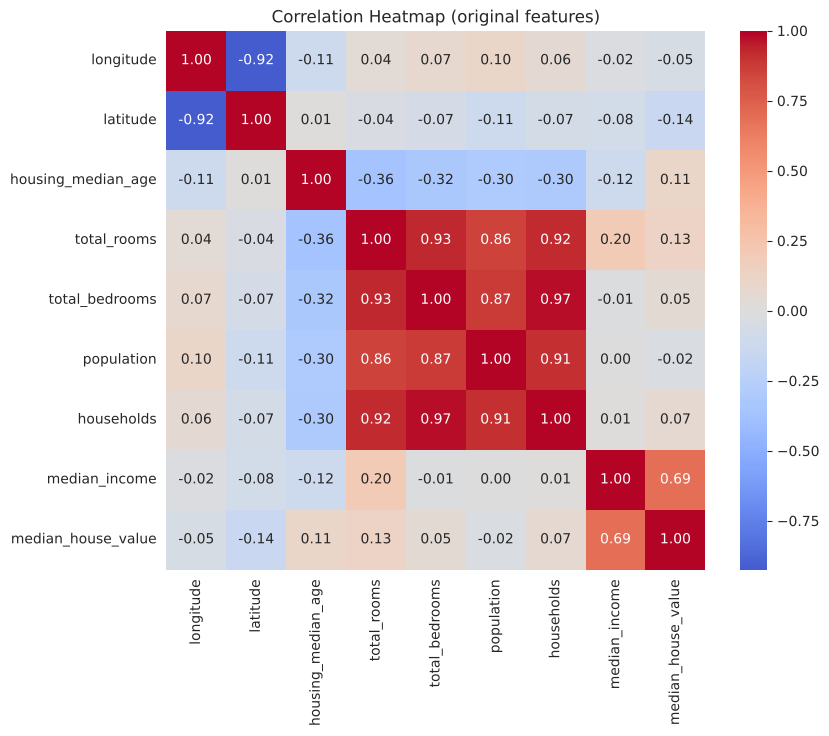

median_house_value    1.000000
median_income         0.688075
total_rooms           0.134153
housing_median_age    0.105623
households            0.065843
total_bedrooms        0.049457
population           -0.024650
longitude            -0.045967
latitude             -0.144160
Name: median_house_value, dtype: float64


In [5]:
eda = df.copy()
eda["total_bedrooms"] = eda["total_bedrooms"].fillna(eda["total_bedrooms"].median())

plt.figure(figsize=(9, 7))
sns.heatmap(eda.select_dtypes("number").corr(), annot=True, fmt=".2f",
            cmap="coolwarm", center=0, square=True)
plt.title("Correlation Heatmap (original features)")
plt.show()

print(eda.select_dtypes("number").corr()["median_house_value"].sort_values(ascending=False))

**Observation:** `total_rooms`, `total_bedrooms`, `population` and `households` are strongly correlated with each other (multicollinearity). `median_income` has the strongest link with house value.

## 5. Multicollinearity check: VIF (before)
**VIF** (Variance Inflation Factor) shows how well a feature can be predicted from the other features. A VIF above about 10 means serious multicollinearity.

In [6]:
def compute_vif(data):
    """VIF = 1 / (1 - R^2) when each feature is regressed on all the others."""
    out = {}
    for col in data.columns:
        others = data.drop(columns=col)
        r2 = LinearRegression().fit(others, data[col]).score(others, data[col])
        out[col] = 1 / (1 - r2) if r2 < 1 else np.inf
    return pd.Series(out, name="VIF").sort_values(ascending=False).round(2)

base_num = ["longitude", "latitude", "housing_median_age", "total_rooms",
            "total_bedrooms", "population", "households", "median_income"]
vif_before = compute_vif(eda[base_num])
vif_before.to_frame()

,VIF
households,28.28
total_bedrooms,26.88
total_rooms,12.13
latitude,8.83
longitude,8.70
population,6.26
median_income,1.69
housing_median_age,1.26


## 6. Feature engineering (interaction / ratio features)
Raw counts depend on the size of the block, so **ratios** describe a neighbourhood better:
- `rooms_per_household`
- `bedrooms_per_room`
- `population_per_household`
- `income_x_rooms` = centered `median_income` × centered `rooms_per_household` (interaction feature; centering keeps it from becoming collinear with its parent features)

The raw count columns (`total_rooms`, `total_bedrooms`, `population`, `households`) are then **dropped** to reduce multicollinearity.

In [7]:
def engineer(data):
    d = data.copy()
    d["rooms_per_household"] = d["total_rooms"] / d["households"]
    d["bedrooms_per_room"] = d["total_bedrooms"] / d["total_rooms"]      # NaN stays NaN -> imputed later
    d["population_per_household"] = d["population"] / d["households"]
    # Interaction on CENTERED values: avoids a big VIF caused by multiplying raw features
    # (means are simple constants from the data, no target information is used)
    d["income_x_rooms"] = (d["median_income"] - 3.8707) * (d["rooms_per_household"] - 5.4290)
    return d.drop(columns=["total_rooms", "total_bedrooms", "population", "households"])

df_fe = engineer(df)
df_fe.head()

,longitude,latitude,housing_median_age,median_income,median_house_value,ocean_proximity,rooms_per_household,bedrooms_per_room,population_per_household,income_x_rooms
0,-122.23,37.88,41.0,8.3252,452600.0,NEAR BAY,6.984127,0.146591,2.555556,6.927313
1,-122.22,37.86,21.0,8.3014,358500.0,NEAR BAY,6.238137,0.155797,2.109842,3.585044
2,-122.24,37.85,52.0,7.2574,352100.0,NEAR BAY,8.288136,0.129516,2.802260,9.683035
3,-122.25,37.85,52.0,5.6431,341300.0,NEAR BAY,5.817352,0.184458,2.547945,0.688314
4,-122.25,37.85,52.0,3.8462,342200.0,NEAR BAY,6.281853,0.172096,2.181467,-0.020895


## 7. Multicollinearity check: VIF (after)

In [8]:
fe_num = ["longitude", "latitude", "housing_median_age", "median_income",
          "rooms_per_household", "bedrooms_per_room",
          "population_per_household", "income_x_rooms"]
tmp = df_fe[fe_num].copy()
tmp = tmp.fillna(tmp.median())

vif_after = compute_vif(tmp)
pd.concat([vif_before.rename("VIF before"), vif_after.rename("VIF after")], axis=1).fillna("-")

,VIF before,VIF after
households,28.28,-
total_bedrooms,26.88,-
total_rooms,12.13,-
latitude,8.83,9.29
longitude,8.7,8.99
population,6.26,-
median_income,1.69,2.69
housing_median_age,1.26,1.12
bedrooms_per_room,-,1.97
income_x_rooms,-,1.43


**Observation:** VIF drops a lot for the count features. `longitude` and `latitude` still stay highly correlated because they describe one geographic area together. Instead of deleting location, **Ridge and Lasso regularization** handles the leftover correlation. This is exactly what the comparison below tests.

## 8. Train/test split (80/20)
We split **before** imputing and scaling, so the test data never leaks into preprocessing.

In [9]:
X = df_fe.drop(columns="median_house_value")
y = df_fe["median_house_value"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=RANDOM_STATE)
print("Train:", X_train.shape, "| Test:", X_test.shape)

Train: (16512, 9) | Test: (4128, 9)


## 9. Preprocessing: impute, standardize, encode
- **Numeric:** median imputation → StandardScaler
- **Categorical** (`ocean_proximity`): One-Hot encoding (`drop='first'` avoids the dummy-variable trap)

In [10]:
num_cols = X.select_dtypes("number").columns.tolist()
cat_cols = ["ocean_proximity"]

preprocess = ColumnTransformer([
    ("num", Pipeline([("imputer", SimpleImputer(strategy="median")),
                      ("scaler", StandardScaler())]), num_cols),
    ("cat", OneHotEncoder(drop="first", handle_unknown="ignore"), cat_cols),
])
print("Numeric:", num_cols)
print("Categorical:", cat_cols)

Numeric: ['longitude', 'latitude', 'housing_median_age', 'median_income', 'rooms_per_household', 'bedrooms_per_room', 'population_per_household', 'income_x_rooms']
Categorical: ['ocean_proximity']


## 10. Train OLS, Ridge and Lasso (GridSearchCV for alpha)
5-fold cross-validation chooses the best `alpha` for Ridge and Lasso. OLS has no hyperparameter.

In [11]:
ols = Pipeline([("prep", preprocess), ("model", LinearRegression())])
ols.fit(X_train, y_train)

ridge_pipe = Pipeline([("prep", preprocess), ("model", Ridge(random_state=RANDOM_STATE))])
ridge_grid = GridSearchCV(ridge_pipe,
                          {"model__alpha": np.logspace(-3, 3, 13)},
                          cv=5, scoring="neg_root_mean_squared_error", n_jobs=-1)
ridge_grid.fit(X_train, y_train)

lasso_pipe = Pipeline([("prep", preprocess),
                       ("model", Lasso(max_iter=50000, random_state=RANDOM_STATE))])
lasso_grid = GridSearchCV(lasso_pipe,
                          {"model__alpha": np.logspace(-2, 3, 13)},
                          cv=5, scoring="neg_root_mean_squared_error", n_jobs=-1)
lasso_grid.fit(X_train, y_train)

print("Best Ridge alpha:", ridge_grid.best_params_["model__alpha"])
print("Best Lasso alpha:", lasso_grid.best_params_["model__alpha"])

Best Ridge alpha: 0.31622776601683794
Best Lasso alpha: 1.2115276586285888


### Alpha vs cross-validated RMSE

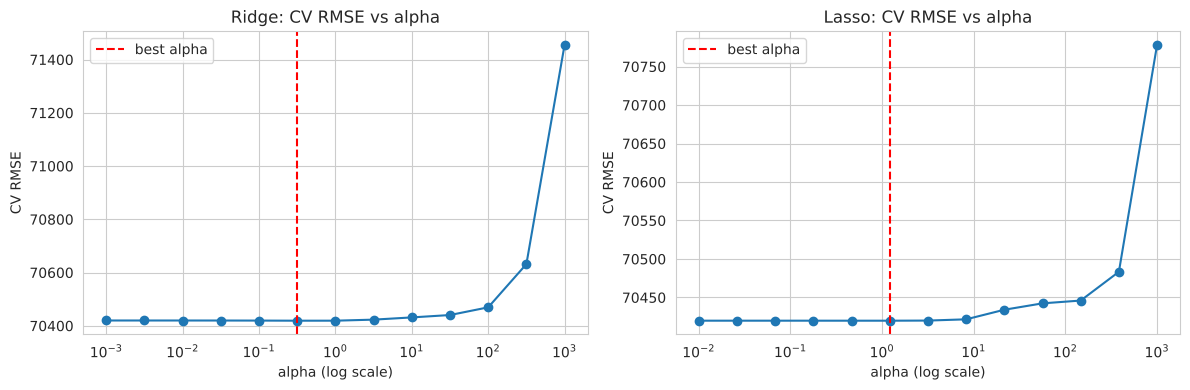

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, grid, name in zip(axes, [ridge_grid, lasso_grid], ["Ridge", "Lasso"]):
    alphas = grid.cv_results_["param_model__alpha"].data.astype(float)
    rmse = -grid.cv_results_["mean_test_score"]
    ax.semilogx(alphas, rmse, marker="o")
    ax.axvline(grid.best_params_["model__alpha"], color="red", ls="--", label="best alpha")
    ax.set_title(f"{name}: CV RMSE vs alpha")
    ax.set_xlabel("alpha (log scale)")
    ax.set_ylabel("CV RMSE")
    ax.legend()
plt.tight_layout()
plt.show()

## 11. Model comparison: RMSE, MAE, R²

In [13]:
models = {"OLS": ols,
          "Ridge (L2)": ridge_grid.best_estimator_,
          "Lasso (L1)": lasso_grid.best_estimator_}

preds, rows = {}, []
for name, m in models.items():
    p = m.predict(X_test)
    preds[name] = p
    rows.append({
        "Model": name,
        "RMSE": np.sqrt(mean_squared_error(y_test, p)),
        "MAE": mean_absolute_error(y_test, p),
        "R²": r2_score(y_test, p),
        "Train R²": r2_score(y_train, m.predict(X_train)),
    })
results = pd.DataFrame(rows).set_index("Model")
results.round(4)

,RMSE,MAE,R²,Train R²
Model,,,,
OLS,71650.9183,51568.3513,0.6082,0.6299
Ridge (L2),71653.7343,51571.3584,0.6082,0.6299
Lasso (L1),71652.3622,51569.7304,0.6082,0.6299


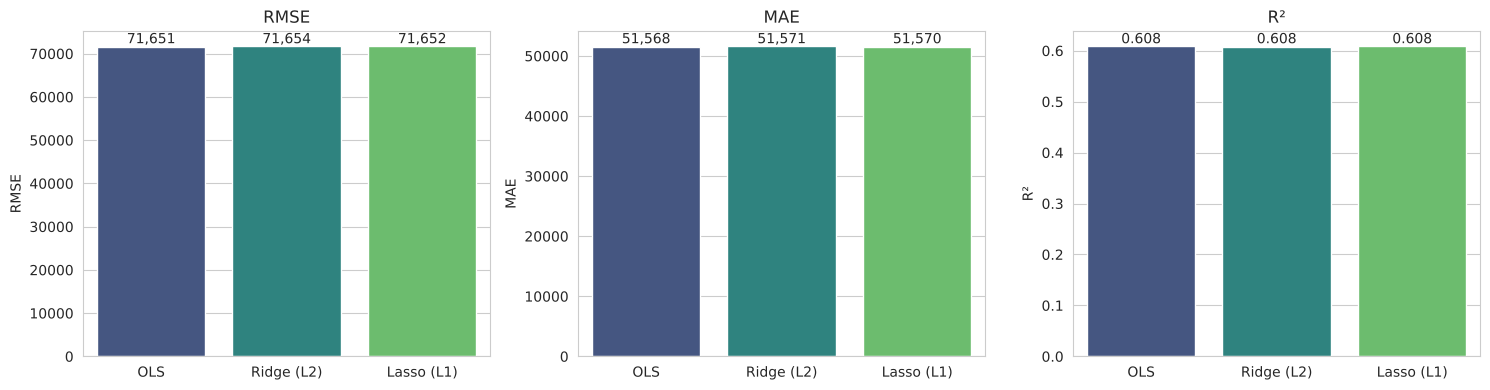

In [14]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, metric in zip(axes, ["RMSE", "MAE", "R²"]):
    sns.barplot(x=results.index, y=results[metric], ax=ax, palette="viridis", hue=results.index, legend=False)
    ax.set_title(metric)
    ax.set_xlabel("")
    for i, v in enumerate(results[metric]):
        ax.text(i, v, f"{v:,.3f}" if metric == "R²" else f"{v:,.0f}", ha="center", va="bottom")
plt.tight_layout()
plt.show()

## 12. Coefficients: how Ridge and Lasso treat features

In [15]:
feature_names = models["OLS"].named_steps["prep"].get_feature_names_out()
coef = pd.DataFrame({name: m.named_steps["model"].coef_ for name, m in models.items()},
                    index=[f.split("__")[1] for f in feature_names]).round(1)
print("Features set to exactly 0 by Lasso:",
      list(coef.index[coef["Lasso (L1)"] == 0]) or "none")
coef

Features set to exactly 0 by Lasso: none


,OLS,Ridge (L2),Lasso (L1)
longitude,-52302.1,-52291.0,-52284.7
latitude,-51208.4,-51198.7,-51189.1
housing_median_age,11448.3,11450.4,11449.4
median_income,87043.1,87038.7,87039.8
rooms_per_household,5429.7,5431.6,5428.3
bedrooms_per_room,21353.8,21353.7,21351.2
population_per_household,-4271.1,-4271.0,-4269.9
income_x_rooms,-7169.9,-7168.1,-7167.5
ocean_proximity_INLAND,-33988.3,-33997.6,-34002.9
ocean_proximity_ISLAND,140238.3,129957.5,135238.4


## 13. Predicted vs Actual

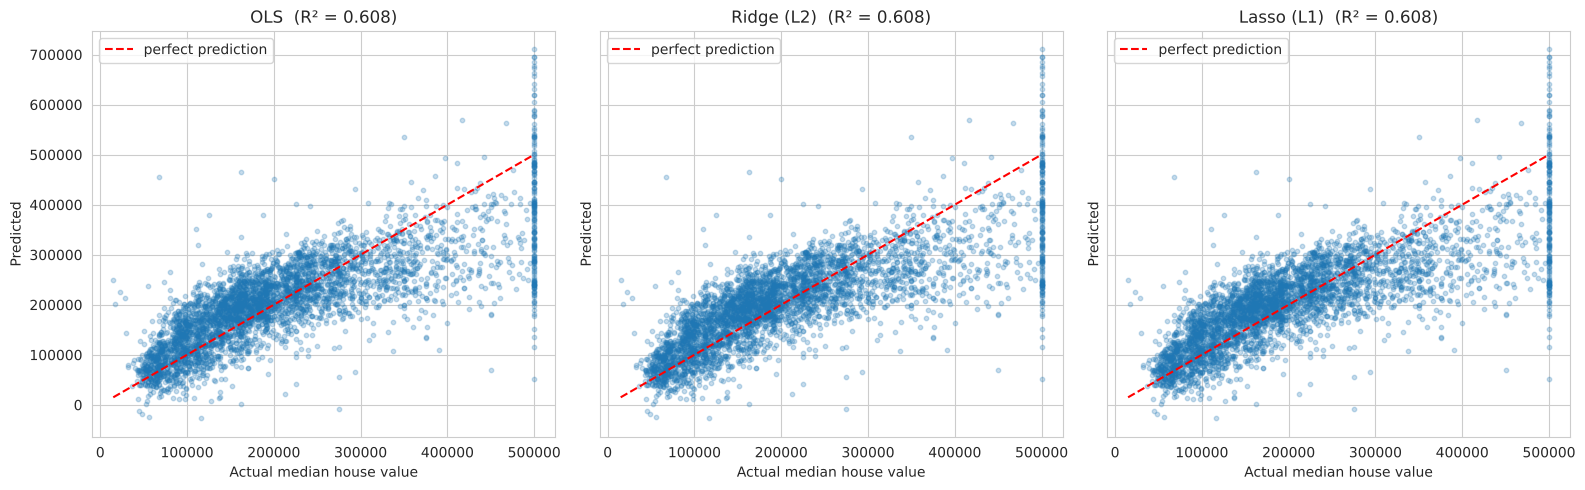

In [16]:
fig, axes = plt.subplots(1, 3, figsize=(16, 5), sharex=True, sharey=True)
lims = [y_test.min(), y_test.max()]
for ax, (name, p) in zip(axes, preds.items()):
    ax.scatter(y_test, p, alpha=0.25, s=10)
    ax.plot(lims, lims, "r--", label="perfect prediction")
    ax.set_title(f"{name}  (R² = {r2_score(y_test, p):.3f})")
    ax.set_xlabel("Actual median house value")
    ax.set_ylabel("Predicted")
    ax.legend()
plt.tight_layout()
plt.show()

## 14. Residual error analysis
Residual = Actual − Predicted. A good model has residuals centred around 0 with no pattern.

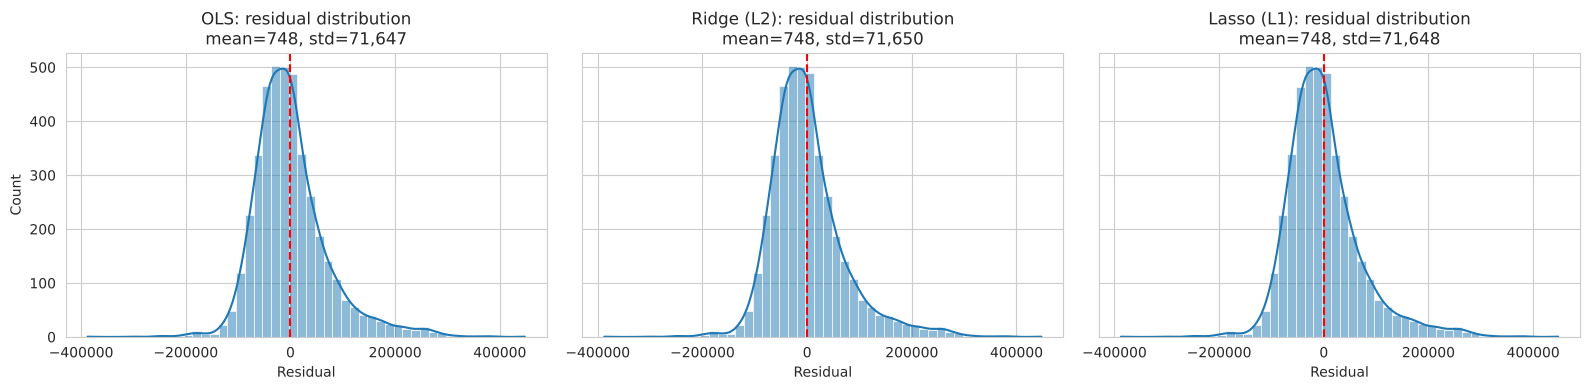

In [17]:
residuals = {name: y_test.values - p for name, p in preds.items()}

fig, axes = plt.subplots(1, 3, figsize=(16, 4), sharex=True, sharey=True)
for ax, (name, r) in zip(axes, residuals.items()):
    sns.histplot(r, kde=True, bins=50, ax=ax)
    ax.axvline(0, color="red", ls="--")
    ax.set_title(f"{name}: residual distribution\nmean={r.mean():,.0f}, std={r.std():,.0f}")
    ax.set_xlabel("Residual")
plt.tight_layout()
plt.show()

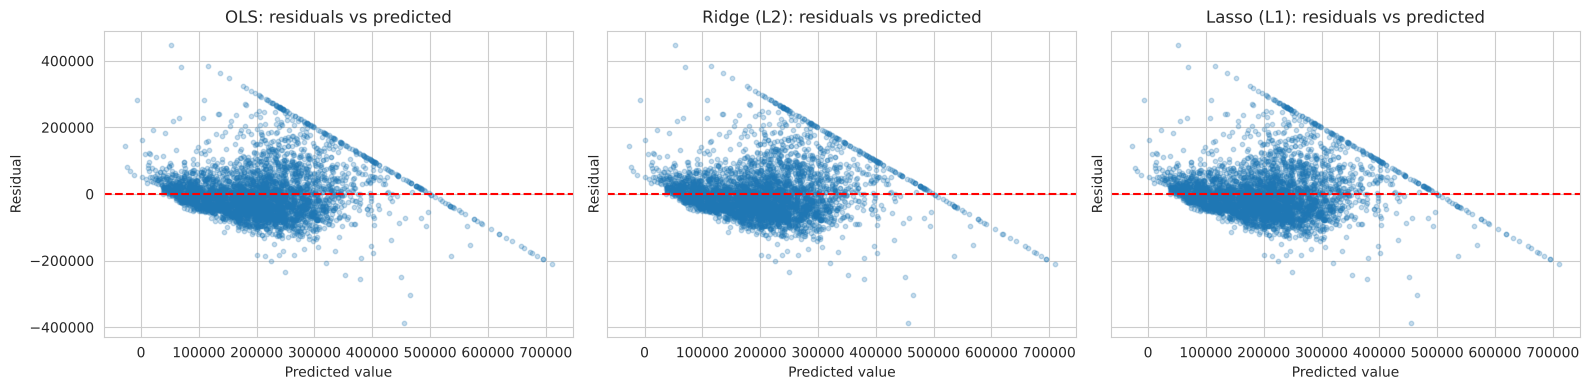

In [18]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4), sharex=True, sharey=True)
for ax, (name, p) in zip(axes, preds.items()):
    ax.scatter(p, residuals[name], alpha=0.25, s=10)
    ax.axhline(0, color="red", ls="--")
    ax.set_title(f"{name}: residuals vs predicted")
    ax.set_xlabel("Predicted value")
    ax.set_ylabel("Residual")
plt.tight_layout()
plt.show()

## 15. Conclusion

In [19]:
print(results.round(4))
best = results["RMSE"].idxmin()
spread = results["RMSE"].max() - results["RMSE"].min()
print(f"\nLowest RMSE: {best}")
print(f"RMSE gap between best and worst model: {spread:,.1f} USD")

                  RMSE         MAE      R²  Train R²
Model                                               
OLS         71650.9183  51568.3513  0.6082    0.6299
Ridge (L2)  71653.7343  51571.3584  0.6082    0.6299
Lasso (L1)  71652.3622  51569.7304  0.6082    0.6299

Lowest RMSE: OLS
RMSE gap between best and worst model: 2.8 USD


**Observations**
- The three models give very similar scores. With about 16,500 training rows and few features, ordinary OLS does not overfit much, so regularization has little room to improve it.
- `median_income` is the most important predictor. Location (`latitude`, `longitude`, `ocean_proximity`) also matters.
- Feature engineering reduced multicollinearity among the count features (see VIF before vs after).
- Residuals are centred near 0, but the spread grows for higher predicted prices. The straight diagonal line in the residual plot and the vertical line at the top of Predicted vs Actual both come from the dataset's price cap of 500,001. A linear model cannot capture this, so non-linear models (Random Forest, Gradient Boosting) would likely do better.
- The `ocean_proximity_ISLAND` coefficient changes between models because only 5 rows belong to that category. Ridge shrinks it the most.
- Lasso can set weak features exactly to 0 (feature selection), while Ridge only shrinks them. Here Lasso kept all features, which means every feature adds some value.